In [51]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

In [37]:
S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.2
N = 100000

In [58]:
# create an array of 50 standard normal distributed values
rng = np.random.default_rng(7)
Z = rng.normal(0, 1, N)

In [39]:
# create function of terminal playoffs S_t
St = S0 * np.exp((r - 0.5 * sigma ** 2) * T + sigma * np.sqrt(T) * Z)



In [40]:
x = np.maximum(St - K, 0)

value_estimate = np.exp(-r*T) * 1/N * np.sum(x)
value_estimate

np.float64(10.406663781668192)

In [41]:
c = 0.95

In [42]:
sigma_estimate = np.std(x, ddof=1)
SE_estimate = np.exp(-r * T) * sigma_estimate / np.sqrt(N)
s = - norm.ppf((1 - c) / 2)

In [43]:
CI = [value_estimate - s * SE_estimate, value_estimate + s * SE_estimate]
print(CI)

[np.float64(10.315813007388371), np.float64(10.497514555948012)]


In [45]:
def calculate_d1_d2(S, K, T, r, sigma):

    d1 = (np.log(S/K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    return d1,d2

In [46]:
def black_scholes_price(S, K, T, r, sigma):  

    d1, d2 = calculate_d1_d2(S, K, T, r, sigma)

    C = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    P = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

    return C,P

In [49]:
bs_price, _ = black_scholes_price(S0, K, T, r, sigma)
print(bs_price)

10.450583572185565


In [ ]:
n_values = np.logspace(2, 5, 50, dtype=int)
rng = np.random.default_rng(4)
M = 100

errors = []
estimates = []

for n in n_values:

    Z = rng.normal(0, 1, size = (M,n))
    St = S0 * np.exp((r - 0.5 * sigma ** 2) * T + sigma * np.sqrt(T) * Z)
    x = np.maximum(St - K, 0)
    value_estimate = np.exp(-r*T) * np.sum(x, axis = 1) / n

    mean_price = np.mean(value_estimate)
    estimates.append(mean_price)

    RMSE_estimate = np.sqrt(np.mean((value_estimate - bs_price)**2))
    errors.append(RMSE_estimate)


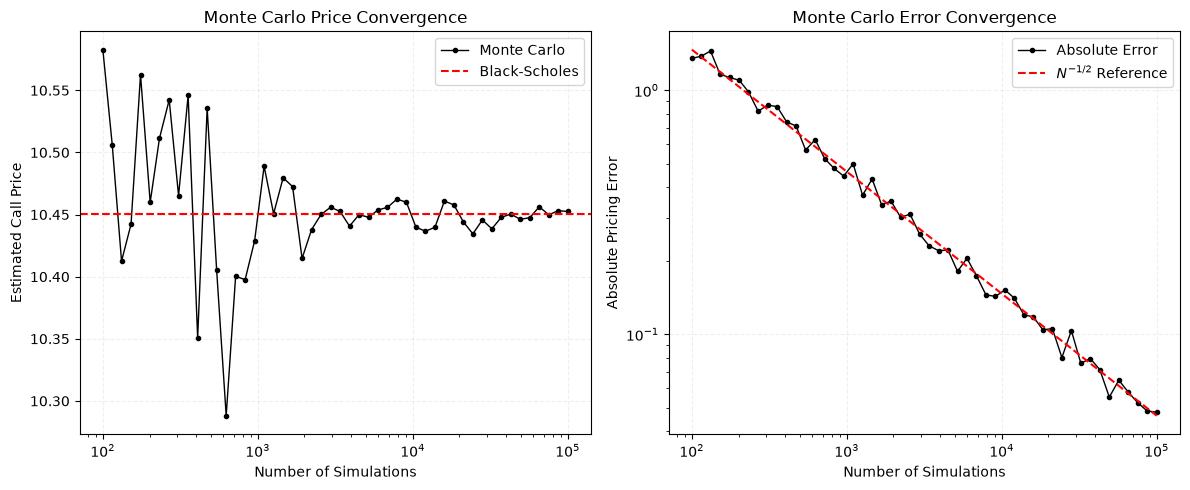

In [129]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Monte Carlo price convergence
axs[0].plot(n_values, estimates, color="black",
            linewidth = 1, marker = ".", label = "Monte Carlo")

axs[0].axhline(bs_price, color="red",
               linestyle = "--", label = "Black-Scholes")

axs[0].set_xscale("log")
axs[0].set_xlabel("Number of Simulations")
axs[0].set_ylabel("Estimated Call Price")
axs[0].set_title("Monte Carlo Price Convergence")
axs[0].legend()
axs[0].grid(alpha = 0.2, linestyle = "--")

# Absolute pricing error
axs[1].plot(n_values, errors, color = "black",
            linewidth = 1, marker = ".", label = "Absolute Error")

axs[1].plot(n_array, reference, color = "red",
            linestyle = "--", linewidth = 1.5,
            label = r"$N^{-1/2}$ Reference")

axs[1].set_xscale("log")
axs[1].set_yscale("log")
axs[1].set_xlabel("Number of Simulations")
axs[1].set_ylabel("Absolute Pricing Error")
axs[1].set_title("Monte Carlo Error Convergence")
axs[1].grid(True, which = "major", alpha = 0.2, linestyle = "--")
axs[1].legend()

plt.tight_layout()
plt.show()